# 03 Modelling and experiments

*Following the ZTM machine learning framework: this notebook continues **Step 5 (Modelling)** and starts **Step 6 (Experiments)**.*

## 5. Modelling: gradient boosting

The baseline logistic regression assumes each feature has a straight-line effect on the log-odds of winning. Cricket doesn't work like that: losing a wicket matters far more with 3 wickets left than with 9, and the same required rate is easier with more balls to play with. A gradient boosted tree model can learn those interactions.

Success criteria from notebook 02: beat logistic regression on log loss and Brier score, and stay calibrated to within about 2 percentage points.

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, brier_score_loss, accuracy_score
from sklearn.calibration import calibration_curve

df = pd.read_csv("data/chases.csv")
normal = df[~df["dls"]].copy()
normal["wickets_left"] = 10 - normal["wickets"]
normal["rrr"] = normal["runs_needed"] / np.maximum(normal["balls_left"], 1) * 6
normal["is_ipl"] = (normal["comp"] == "ipl").astype(int)

# same split as 02 so the comparison is fair
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(normal, groups=normal["match_id"]))
train, test = normal.iloc[train_idx], normal.iloc[test_idx]

features = ["runs_needed", "balls_left", "wickets_left", "rrr", "is_ipl"]
X_train, y_train = train[features], train["won"]
X_test, y_test = test[features], test["won"]

### Training

**Monotonic constraints** build in cricket common sense: more runs needed can never *raise* the chance of winning, and more balls or wickets left can never *lower* it. This stops the model learning odd wiggles from noise, and makes it safer on the unusual match states DLS games produce.

**Early stopping** holds back part of the training data and stops adding trees once the score on it stops improving.

In [2]:
# features: runs_needed, balls_left, wickets_left, rrr, is_ipl
# +1 = can only increase win prob, -1 = can only decrease, 0 = unconstrained
monotonic = [-1, 1, 1, -1, 0]

gbm = HistGradientBoostingClassifier(
    max_iter=500,
    learning_rate=0.05,
    monotonic_cst=monotonic,
    early_stopping=True,
    random_state=42,
)
gbm.fit(X_train, y_train)
lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)

p_lr = lr.predict_proba(X_test)[:, 1]
p_gbm = gbm.predict_proba(X_test)[:, 1]

print("trees used:", gbm.n_iter_)
for name, p in [("logreg", p_lr), ("gbm", p_gbm)]:
    print(f"{name:7} log loss {log_loss(y_test, p):.4f}  brier {brier_score_loss(y_test, p):.4f}  acc {accuracy_score(y_test, p > 0.5):.3f}")

trees used: 329
logreg  log loss 0.3816  brier 0.1247  acc 0.817
gbm     log loss 0.3796  brier 0.1248  acc 0.817


## 6. Experiments

### Where in the chase does it improve?

Late in a chase most outcomes are obvious, which flatters any model. Splitting the test set by phase shows whether the gain holds up while the game is still open.

In [3]:
phase = pd.cut(test["balls_left"], [-1, 36, 84, 120],
               labels=["death (0-6 overs left)", "middle (7-14)", "early (15-20)"])
rows = []
for ph in phase.cat.categories:
    m = (phase == ph).values
    rows.append({"phase": ph, "balls": m.sum(),
                 "logreg": log_loss(y_test[m], p_lr[m]),
                 "gbm": log_loss(y_test[m], p_gbm[m])})
pd.DataFrame(rows).round(4)

,phase,balls,logreg,gbm
0,death (0-6 overs left),24400,0.2504,0.2436
1,middle (7-14),42756,0.3799,0.3821
2,early (15-20),33189,0.4802,0.4765


### Calibration

Group predictions into bins and compare the average predicted win probability with how often those teams actually won. A perfectly calibrated model sits on the diagonal: when it says 70%, teams win 70% of the time. The DLS test depends on this.

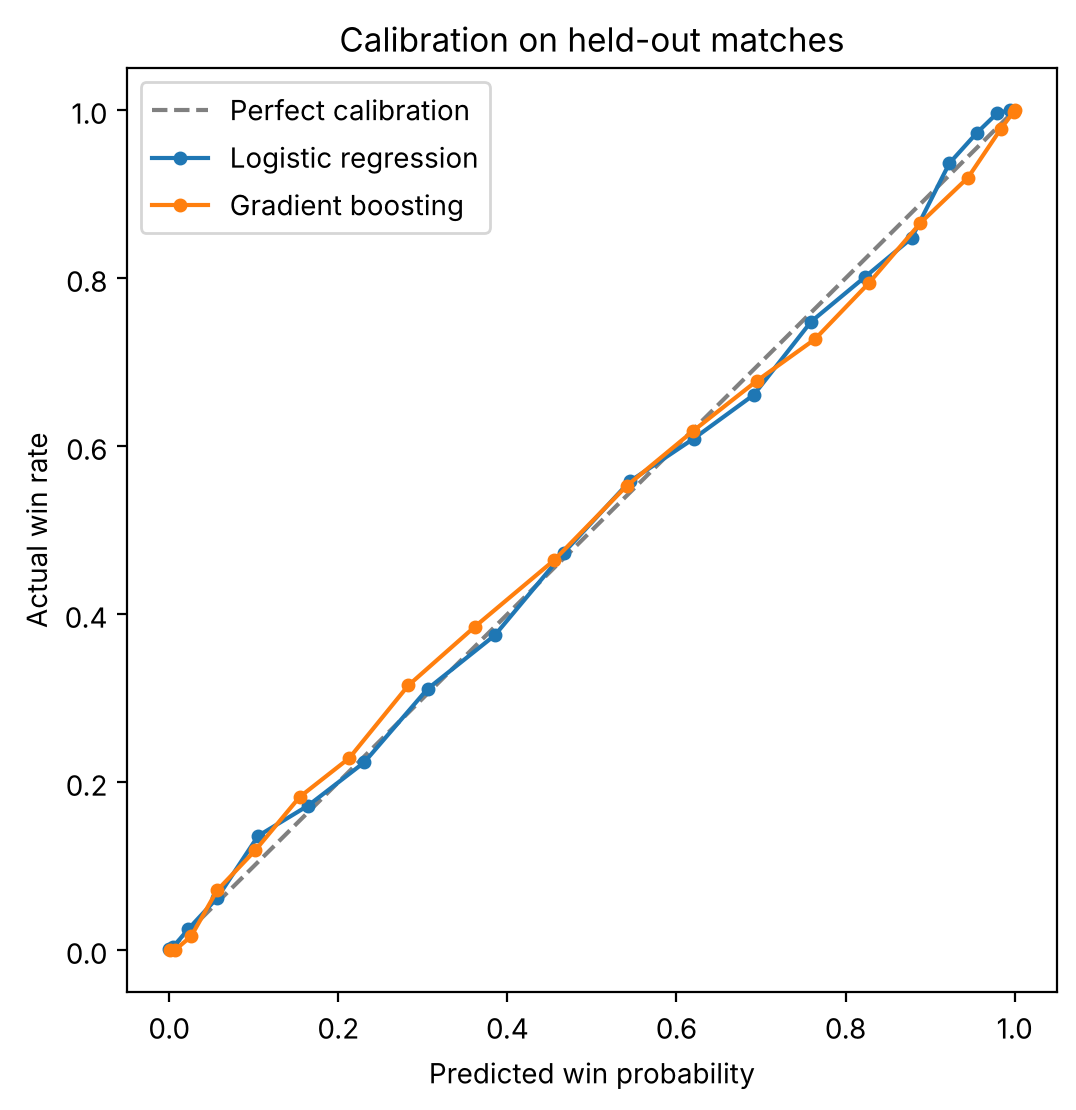

Logistic regression: average gap 1.3 pp, worst bin 3.1 pp
Gradient boosting: average gap 1.6 pp, worst bin 3.6 pp


In [4]:
os.makedirs("figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
gaps = {}
for name, p in [("Logistic regression", p_lr), ("Gradient boosting", p_gbm)]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=20, strategy="quantile")
    gaps[name] = (np.mean(np.abs(frac - mean_pred)), np.max(np.abs(frac - mean_pred)))
    ax.plot(mean_pred, frac, "o-", ms=4, label=name)
ax.set_xlabel("Predicted win probability")
ax.set_ylabel("Actual win rate")
ax.set_title("Calibration on held-out matches")
ax.legend()
plt.savefig("figures/calibration.png", dpi=150, bbox_inches="tight")
plt.show()

for name, (avg, worst) in gaps.items():
    print(f"{name}: average gap {avg*100:.1f} pp, worst bin {worst*100:.1f} pp")

### Experiment: adding the target as a feature

The first-innings total says something about the pitch and conditions, so it might help. The catch: it's the same for every ball in a match, so the model could use it to memorise individual matches instead of learning general patterns.

In [5]:
features_t = features + ["target"]
gbm_t = HistGradientBoostingClassifier(
    max_iter=1000, learning_rate=0.05, monotonic_cst=monotonic + [0],
    early_stopping=True, random_state=42,
).fit(train[features_t], y_train)
p_t = gbm_t.predict_proba(test[features_t])[:, 1]
print(f"gbm + target  log loss {log_loss(y_test, p_t):.4f}  brier {brier_score_loss(y_test, p_t):.4f}")

gbm + target  log loss 0.4117  brier 0.1297


### Sense check on familiar situations

Win probabilities for a few chase situations, compared with how teams in similar spots actually did (within 3 runs and 2 balls, same wickets, all normal matches). An exact situation happens too rarely to compare on its own.

In [6]:
cases = pd.DataFrame([
    {"situation": "need 180 off 120, 10 wkts left", "runs_needed": 180, "balls_left": 120, "wickets_left": 10},
    {"situation": "need 60 off 36, 7 wkts left",    "runs_needed": 60,  "balls_left": 36,  "wickets_left": 7},
    {"situation": "need 60 off 36, 3 wkts left",    "runs_needed": 60,  "balls_left": 36,  "wickets_left": 3},
    {"situation": "need 12 off 6, 5 wkts left",     "runs_needed": 12,  "balls_left": 6,   "wickets_left": 5},
    {"situation": "need 2 off 6, 8 wkts left",      "runs_needed": 2,   "balls_left": 6,   "wickets_left": 8},
])
cases["rrr"] = cases["runs_needed"] / np.maximum(cases["balls_left"], 1) * 6
cases["is_ipl"] = 0
cases["model win %"] = (gbm.predict_proba(cases[features])[:, 1] * 100).round(1)

normal["p"] = gbm.predict_proba(normal[features])[:, 1]
for i, c in cases.iterrows():
    near = normal[normal["runs_needed"].between(c.runs_needed - 3, c.runs_needed + 3)
                  & normal["balls_left"].between(c.balls_left - 2, c.balls_left + 2)
                  & (normal["wickets_left"] == c.wickets_left)]
    cases.loc[i, "similar: model %"] = round(near["p"].mean() * 100, 1)
    cases.loc[i, "similar: actual %"] = round(near["won"].mean() * 100, 1)
    cases.loc[i, "matches"] = near["match_id"].nunique()
cases[["situation", "model win %", "similar: model %", "similar: actual %", "matches"]]

,situation,model win %,similar: model %,similar: actual %,matches
0,"need 180 off 120, 10 wkts left",28.5,35.1,32.2,321.0
1,"need 60 off 36, 7 wkts left",45.9,54.9,53.0,151.0
2,"need 60 off 36, 3 wkts left",4.6,5.2,5.6,34.0
3,"need 12 off 6, 5 wkts left",51.4,61.7,59.4,165.0
4,"need 2 off 6, 8 wkts left",100.0,99.9,96.0,43.0


## Results

| Model | Log loss | Brier | Avg calibration gap | Worst bin |
|---|---|---|---|---|
| Dumb baseline | 0.694 | 0.250 | | |
| Logistic regression | 0.382 | 0.125 | 1.3 pp | 3.1 pp |
| Gradient boosting | **0.380** | 0.125 | 1.6 pp | 3.6 pp |
| Gradient boosting + target | 0.412 | 0.130 | | |

- **Gradient boosting only just beats logistic regression** on log loss and ties on Brier score. Nearly all the predictable signal is in runs needed, balls left and wickets left, and a simple model already captures most of it. The rest is the genuine randomness of cricket, which no model can remove.
- **Its gain comes at the ends of the chase** (early and death overs), where the effect of wickets is least linear. It's slightly worse in the middle overs.
- **Calibration:** on average predictions are within about 1.5 percentage points of reality, but the worst bin is out by 3.6, so the 2-point target from notebook 02 is **not fully met**. Part of this is noise: balls from the same match aren't independent, so each bin effectively holds a few hundred matches, not thousands of balls. It still means DLS results within a few points of 50% shouldn't be treated as meaningful.
- **Adding the target made things worse**, as feared: the model overfit to match-level information.
- **The sense checks match the data:** across similar real situations, the model's average prediction is within a few points of how often those teams actually won.

Gradient boosting is kept for the DLS test. The scores are nearly tied, but its monotonic constraints keep it sensible in the unusual reduced-overs situations DLS creates, where a straight-line model can extrapolate badly.

### Saving the model

Saved so notebook 04 can load it for the DLS test without retraining. The file is regenerated by running this notebook, so it isn't committed to the repo.

In [7]:
os.makedirs("models", exist_ok=True)
joblib.dump(gbm, "models/gbm.joblib")

['models/gbm.joblib']